C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = RestrictedUnpickler(f, encoding="bytes").load()


Training Data: (50000, 32, 32, 3)
Testing Data: (10000, 32, 32, 3)


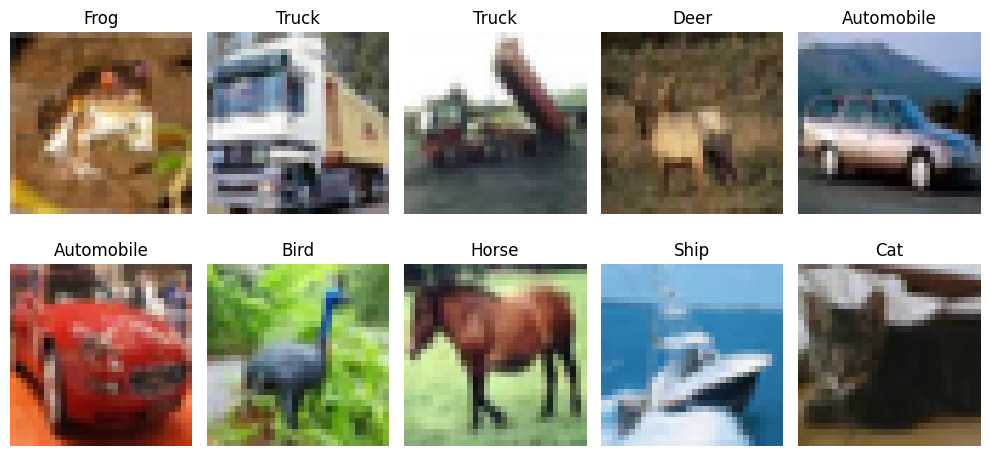


CNN WITHOUT BN AND DROPOUT


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 4, 4, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 1,144,298 (4.37 MB)

 Trainable params: 1,143,594 (4.36 MB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 141s 174ms/step - accuracy: 0.4221 - loss: 1.6236 - val_accuracy: 0.5656 - val_loss: 1.2083
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 103s 119ms/step - accuracy: 0.5243 - loss: 1.3379 - val_accuracy: 0.4924 - val_loss: 1.4581
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 139s 115ms/step - accuracy: 0.5622 - loss: 1.2276 - val_accuracy: 0.6098 - val_loss: 1.0867
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 83s 117ms/step - accuracy: 0.5920 - loss: 1.1528 - val_accuracy: 0.6148 - val_loss: 1.0746
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 112ms/step - accuracy: 0.6436 - loss: 1.0211 - val_accuracy: 0.7178 - val_loss: 0.8067
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 80s 109ms/step - accuracy: 0.6500 - loss: 0.9956 - val_accuracy: 0.7206 - val_loss: 0.7972
Epoch 9/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 91s 121ms/step - accuracy: 0.6644 - loss: 0.9628 - val_accuracy: 0.6882 - val_loss: 0.9513
Epoch 10/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 138s 116ms/step - accuracy: 0.6738 - lo

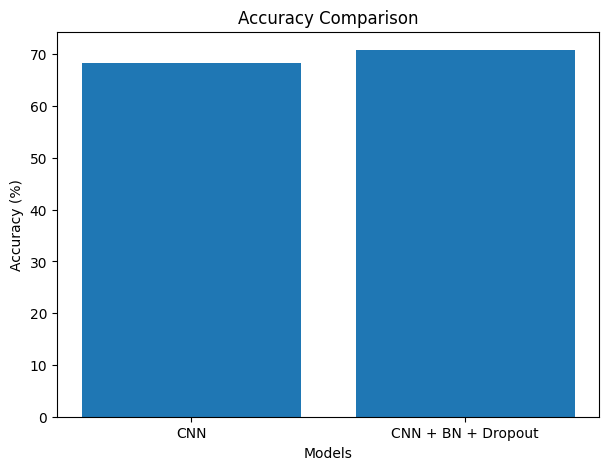

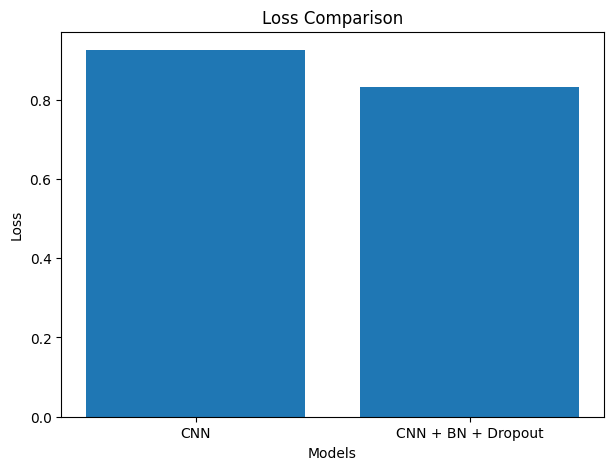

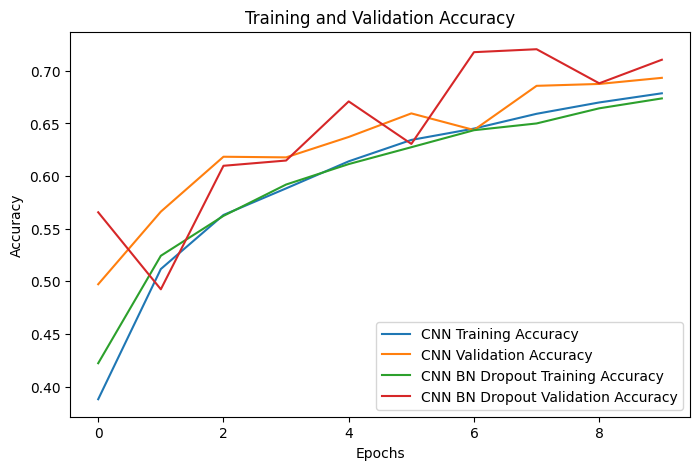

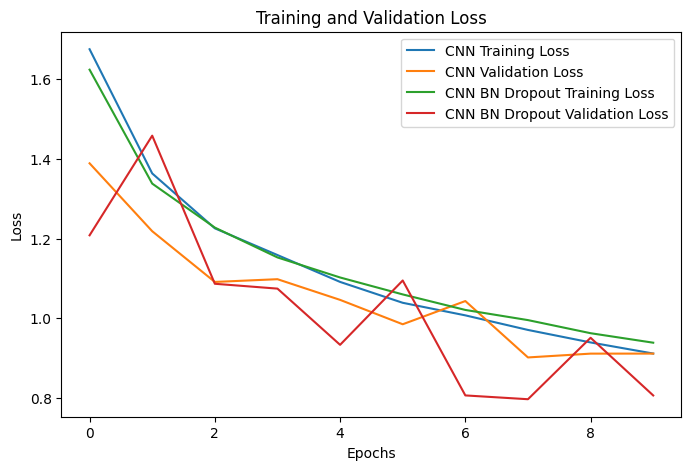

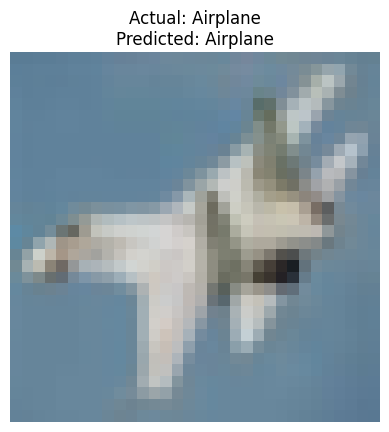

Actual Class: Airplane
Predicted Class: Airplane

CNN with Batch Normalization and Dropout performed better.

Experiment Completed Successfully!


In [1]:
# ============================================
# EXPERIMENT:
# OBJECT RECOGNITION USING CNN (CIFAR-10)
# ============================================

# 1. Import Libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout,
    BatchNormalization, RandomFlip,
    RandomRotation
)


# 2. Load CIFAR-10 Dataset

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)


# 3. Normalize Dataset

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0


# 4. Define Class Names

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]


# 5. Display Sample Images

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================
# 6. DATA AUGMENTATION
# ============================================

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1)
])


# ============================================
# 7. CNN WITHOUT BATCH NORMALIZATION
#    AND DROPOUT
# ============================================

cnn_model = Sequential([

    Input(shape=(32, 32, 3)),

    # Data Augmentation
    data_augmentation,

    # First Convolution Layer
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Second Convolution Layer
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Third Convolution Layer
    Conv2D(128, (3, 3), activation="relu"),

    Flatten(),

    Dense(128, activation="relu"),

    Dense(10, activation="softmax")
])


# Compile Model

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nCNN WITHOUT BN AND DROPOUT")
cnn_model.summary()


# Train Model

history_cnn = cnn_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)


# Evaluate Model

cnn_loss, cnn_accuracy = cnn_model.evaluate(
    x_test, y_test, verbose=0
)


# ============================================
# 8. CNN WITH BATCH NORMALIZATION AND DROPOUT
# ============================================

cnn_bn_model = Sequential([

    Input(shape=(32, 32, 3)),

    # Data Augmentation
    data_augmentation,

    # First Convolution Block
    Conv2D(32, (3, 3), padding="same", use_bias=False),
    BatchNormalization(),
    tf.keras.layers.ReLU(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Second Convolution Block
    Conv2D(64, (3, 3), padding="same", use_bias=False),
    BatchNormalization(),
    tf.keras.layers.ReLU(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Third Convolution Block
    Conv2D(128, (3, 3), padding="same", use_bias=False),
    BatchNormalization(),
    tf.keras.layers.ReLU(),

    Flatten(),

    Dense(128, use_bias=False),
    BatchNormalization(),
    tf.keras.layers.ReLU(),

    Dropout(0.5),

    Dense(10, activation="softmax")
])


# Compile Model

cnn_bn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nCNN WITH BN AND DROPOUT")
cnn_bn_model.summary()


# Train Model

history_bn = cnn_bn_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)


# Evaluate Model

bn_loss, bn_accuracy = cnn_bn_model.evaluate(
    x_test, y_test, verbose=0
)


# ============================================
# 9. PERFORMANCE COMPARISON
# ============================================

print("\n========== PERFORMANCE ANALYSIS ==========")

print("CNN Accuracy:",
      round(cnn_accuracy * 100, 2), "%")

print("CNN with BN and Dropout Accuracy:",
      round(bn_accuracy * 100, 2), "%")

print("\nCNN Loss:", round(cnn_loss, 4))

print("CNN with BN and Dropout Loss:",
      round(bn_loss, 4))


# ============================================
# 10. ACCURACY COMPARISON GRAPH
# ============================================

models = ["CNN", "CNN + BN + Dropout"]

accuracies = [
    cnn_accuracy * 100,
    bn_accuracy * 100
]

plt.figure(figsize=(7, 5))

plt.bar(models, accuracies)

plt.title("Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy (%)")

plt.show()


# ============================================
# 11. LOSS COMPARISON GRAPH
# ============================================

losses = [cnn_loss, bn_loss]

plt.figure(figsize=(7, 5))

plt.bar(models, losses)

plt.title("Loss Comparison")
plt.xlabel("Models")
plt.ylabel("Loss")

plt.show()


# ============================================
# 12. TRAINING AND VALIDATION ACCURACY
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["accuracy"],
    label="CNN Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="CNN Validation Accuracy"
)

plt.plot(
    history_bn.history["accuracy"],
    label="CNN BN Dropout Training Accuracy"
)

plt.plot(
    history_bn.history["val_accuracy"],
    label="CNN BN Dropout Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()


# ============================================
# 13. TRAINING AND VALIDATION LOSS
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["loss"],
    label="CNN Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="CNN Validation Loss"
)

plt.plot(
    history_bn.history["loss"],
    label="CNN BN Dropout Training Loss"
)

plt.plot(
    history_bn.history["val_loss"],
    label="CNN BN Dropout Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()


# ============================================
# 14. PREDICT SAMPLE IMAGE
# ============================================

index = 10

prediction = cnn_bn_model.predict(
    x_test[index:index+1],
    verbose=0
)

predicted_class = np.argmax(prediction)

actual_class = int(y_test[index][0])

plt.imshow(x_test[index])

plt.title(
    "Actual: " + class_names[actual_class] +
    "\nPredicted: " + class_names[predicted_class]
)

plt.axis("off")
plt.show()

print("Actual Class:", class_names[actual_class])

print("Predicted Class:", class_names[predicted_class])


# ============================================
# 15. FINAL RESULT
# ============================================

if bn_accuracy > cnn_accuracy:
    print("\nCNN with Batch Normalization and Dropout "
          "performed better.")
else:
    print("\nCNN without Batch Normalization and Dropout "
          "performed better.")

print("\nExperiment Completed Successfully!")